# First neural-data pilot: STRF and CNN probing
Small Wingert-method pilot, **not a full paper reproduction**.

Twenty CLT027c neurons; ten unique 22-s training sequences; one separate 22-s
sequence averaged over two repeats for testing. Models have eight shared channels
and receive 30 fitting epochs (15 per stage), one seed, and no jackknife ensemble.
The test data do not select a unit or tune fitting settings. We inspect unit 0.

Job 7235 completed on a Slurm compute node. TensorFlow used CPU because its CUDA
libraries were not yet installed; this is recorded in the run metadata.


In [1]:
import os
import sys
import json
from pathlib import Path
os.environ.update(MPLCONFIGDIR="/tmp/speech-mpl", XDG_CACHE_HOME="/tmp/speech-cache")
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "03_src/strf.py").exists())
sys.path.insert(0, str(root / "03_src"))
import numpy as np
import matplotlib.pyplot as plt
from strf import load_site, prediction_correlation
from nems.tools.json import load_model
run = root / "04_checkpoints/wingert_pilot_seed0"
metrics = json.loads((run / "metrics.json").read_text())
unit = 0
print(metrics["cellids"][unit], "| job", metrics["job_id"])
print("Median test r:", {k: round(float(np.nanmedian(metrics[k + "_test_r"])), 3)
                         for k in ["LN", "CNN"]})


CLT027c-009-1 | job 7235
Median test r: {'LN': 0.039, 'CNN': 0.131}


## Held-out predictions
Pearson correlations pool test time bins after excluding the first 25 bins.
These are plain correlations, without the paper's repeat-noise correction.
The trace below is the preselected unit 0; the scatter includes all 20 neurons.
With only one short test sequence, small differences are exploratory.


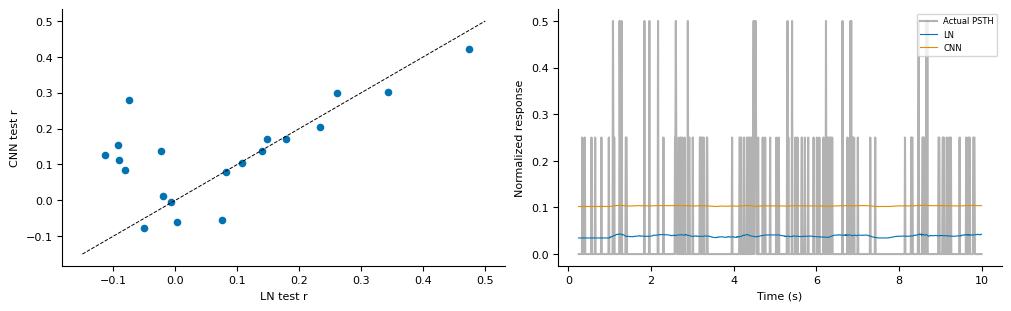

In [2]:
_, _, x_test, y_test, _, _ = load_site()
models = {k: load_model(str(run / f"{k}.json")) for k in ["LN", "CNN"]}
pred = {k: m.predict(x_test, batch_size=len(x_test)) for k, m in models.items()}
for k in models:
    np.testing.assert_allclose(prediction_correlation(pred[k], y_test),
                               metrics[k + "_test_r"], atol=1e-5)
fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
r_ln, r_cnn = np.array(metrics["LN_test_r"]), np.array(metrics["CNN_test_r"])
axes[0].scatter(r_ln, r_cnn, s=20)
axes[0].plot([-.15, .5], [-.15, .5], "k--", linewidth=.7)
axes[0].set(xlabel="LN test r", ylabel="CNN test r")
t = np.arange(25, 1000) / 100
axes[1].plot(t, y_test[0, 25:1000, unit], color="gray", label="Actual PSTH", alpha=.6)
for k in pred:
    axes[1].plot(t, pred[k][0, 25:1000, unit], label=k, linewidth=.8)
axes[1].set(xlabel="Time (s)", ylabel="Normalized response")
axes[1].legend()
out = root / "05_results/wingert_pilot"
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "predictions.png", dpi=150)
plt.show()


## Learned STRF and context-dependent filters
The LN STRF is its fixed **pre-nonlinearity** filter, assembled from spectral,
temporal, and readout weights. The CNN dSTRFs are **post-nonlinearity** local
sensitivities and can change in both shape and gain. Their magnitudes are not
directly comparable. PCA below describes variation in 64 training contexts only.


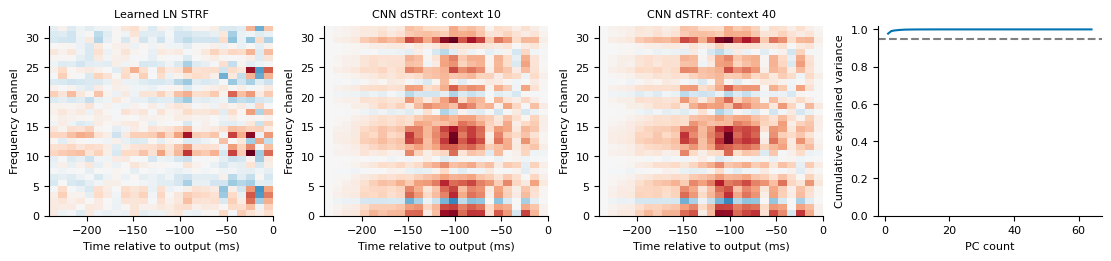

Unit-0 sampled k95: 1


In [3]:
h = np.load(run / "LN_strfs.npy")[unit]
probe = np.load(run / "unit0_probe.npz")
d = probe["dstrf"]
np.testing.assert_allclose(np.linalg.norm(probe["components"], axis=1), 1, atol=1e-5)
fig, axes = plt.subplots(1, 4, figsize=(11, 2.5), constrained_layout=True)
for ax, filt, title in zip(axes[:3], [h, d[10], d[40]],
                           ["Learned LN STRF", "CNN dSTRF: context 10", "CNN dSTRF: context 40"]):
    limit = max(np.abs(filt).max(), 1e-9)
    ax.imshow(filt, origin="lower", aspect="auto", cmap="RdBu_r", vmin=-limit, vmax=limit,
              extent=[-240, 0, 0, 32])
    ax.set(title=title, xlabel="Time relative to output (ms)", ylabel="Frequency channel")
axes[3].plot(np.arange(1, len(probe["cumulative"]) + 1), probe["cumulative"])
axes[3].axhline(.95, color="gray", linestyle="--")
axes[3].set(xlabel="PC count", ylabel="Cumulative explained variance", ylim=(0, 1.02))
fig.savefig(out / "learned_filters.png", dpi=150)
plt.show()
print("Unit-0 sampled k95:", metrics["unit0_dstrf_k95"])


## What this establishes
The small pipeline can fit both models, predict held-out responses, recover a fixed
LN STRF, and extract CNN gradients on real stimuli. A larger CNN advantage or a
stable multi-dimensional subspace is **not established** by this short pilot.
Unit 0 requires only one centered PCA direction at this fit stage; that can reflect
gain changes and underfitting, not a biological one-dimensional computation.

GPU inference and gradient checks subsequently passed in job 7236.
Next: assess convergence using training-only validation
before increasing the model width or measuring more neurons. Keep the final test
sequence untouched for model selection. SSRF fitting and population analysis follow later.
